# [Dataset : Sneakers Classification](https://www.kaggle.com/datasets/nikolasgegenava/sneakers-classification)

**Pasul 1.** Citirea bibliotecilor necesare și vizualizarea informației despre mapa cu imagini

In [228]:
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pathlib
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder 

In [229]:
# # Download the dataset using kagglehub
# dataset_path = kagglehub.dataset_download("vishweshsalodkar/wild-animals")
# print("Path to dataset files:", dataset_path)
# dataset_path = os.path.join(dataset_path, 'Animals')

In [230]:
# Download the dataset using kagglehub
dataset_path = kagglehub.dataset_download("nikolasgegenava/sneakers-classification")
print("Path to dataset files:", dataset_path)
dataset_path = os.path.join(dataset_path, 'sneakers-dataset/sneakers-dataset')

Path to dataset files: /home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2


In [231]:
# define image size and batch size
IMG_SIZE = 224
BATCH_SIZE = 32

In [232]:
# 1. List all directories in dataset_path
try:
    all_items = os.listdir(dataset_path)
    NUM_CLASSES = len(all_items)
except FileNotFoundError:
    print(f"Error: The dataset path '{dataset_path}' was not found.")
else:
    directories = [item for item in all_items if os.path.isdir(os.path.join(dataset_path, item))]

    # 2. For each directory, count and display the number of items
    for folder_name in directories:
        folder_path = os.path.join(dataset_path, folder_name)
        num_items = len(os.listdir(folder_path))
        print(f"The directory '{folder_name}' contains {num_items} items.")

print(f"Num Classes: {NUM_CLASSES}")

The directory 'yeezy_700_wave_runner' contains 108 items.
The directory 'adidas_forum_low' contains 92 items.
The directory 'adidas_gazelle' contains 149 items.
The directory 'new_balance_550' contains 150 items.
The directory 'converse_chuck_70_low' contains 148 items.
The directory 'adidas_superstar' contains 93 items.
The directory 'new_balance_574' contains 150 items.
The directory 'adidas_ultraboost' contains 150 items.
The directory 'nike_air_jordan_3' contains 100 items.
The directory 'nike_air_jordan_1_high' contains 77 items.
The directory 'nike_dunk_low' contains 80 items.
The directory 'yeezy_slide' contains 145 items.
The directory 'new_balance_990' contains 95 items.
The directory 'converse_chuck_taylor_all-star_high' contains 78 items.
The directory 'nike_air_max_270' contains 149 items.
The directory 'new_balance_992' contains 150 items.
The directory 'nike_air_max_plus_(tn)' contains 93 items.
The directory 'converse_one_star' contains 150 items.
The directory 'adidas_n

In [233]:
DataPath = pathlib.Path(dataset_path)
all_paths = DataPath.glob("*/*.j*g") # aici avem si jpg si jpeg
all_paths

<generator object Path.glob at 0x705eac26d4a0>

**Pasul 2.**  Citirea primelor 10 imagini din fișie

In [234]:
all_paths = list(all_paths)
print(len(all_paths))
all_paths[:5]

5944


[PosixPath('/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0073.jpg'),
 PosixPath('/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0023.jpg'),
 PosixPath('/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0102.jpg'),
 PosixPath('/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0076.jpg'),
 PosixPath('/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0049.jpg')]

In [235]:
all_paths = list(map(lambda x : str(x), all_paths))
all_paths[:5]

['/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0073.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0023.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0102.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0076.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0049.jpg']

**Pasul 3.** Amestecarea imaginilor în fișier cu scopul evitării antrenării rețelei doar pe un anumit
tip de imagini :

In [236]:
from random import shuffle

shuffle(all_paths)
print(len(all_paths))
all_paths[:5]

5944


['/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/converse_chuck_70_low/0055.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/salomon_xt-6/0081.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/converse_one_star/0117.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/nike_air_max_270/0148.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/nike_air_max_90/0138.jpg']

**Pasul 4.** Decodarea imaginilor :

In [237]:
def FilterValidImages(all_paths):
    new_all_paths = []
    for path in tqdm(all_paths):
        try:
            image = tf.io.read_file(path)
            image = tf.io.decode_jpeg(image, channels = 3)
        except:
            continue
        new_all_paths.append(path)
    return new_all_paths

all_paths = FilterValidImages(all_paths)
all_paths[:5]

100%|██████████| 5944/5944 [00:02<00:00, 2219.47it/s]


['/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/converse_chuck_70_low/0055.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/salomon_xt-6/0081.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/converse_one_star/0117.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/nike_air_max_270/0148.jpg',
 '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/nike_air_max_90/0138.jpg']

**Pasul 5.** Obținerea etichetelor și transformarea lor în 0 și 1

In [238]:
def get_label(image_path):
    return image_path.split("/")[-2]

all_labels = list(map(lambda x : get_label(x), all_paths))
all_labels[:10]

['converse_chuck_70_low',
 'salomon_xt-6',
 'converse_one_star',
 'nike_air_max_270',
 'nike_air_max_90',
 'converse_chuck_taylor_all-star_low',
 'new_balance_574',
 'yeezy_700_wave_runner',
 'adidas_stan_smith',
 'new_balance_550']

In [239]:
# from sklearn.preprocessing import LabelEncoder

Le = LabelEncoder()
all_labels = Le.fit_transform(all_labels)

all_labels[:10]

array([10, 42, 13, 28, 29, 12, 16, 47,  5, 15])

In [240]:
# Din interes sportiv vom vedea ce numere au primit fiecare clasa
label_mapping = dict(zip(Le.classes_, Le.transform(Le.classes_)))
for label, encoded in label_mapping.items():
    print(f"{encoded} -> {label}")

0 -> adidas_forum_high
1 -> adidas_forum_low
2 -> adidas_gazelle
3 -> adidas_nmd_r1
4 -> adidas_samba
5 -> adidas_stan_smith
6 -> adidas_superstar
7 -> adidas_ultraboost
8 -> asics_gel-lyte_iii
9 -> converse_chuck_70_high
10 -> converse_chuck_70_low
11 -> converse_chuck_taylor_all-star_high
12 -> converse_chuck_taylor_all-star_low
13 -> converse_one_star
14 -> new_balance_327
15 -> new_balance_550
16 -> new_balance_574
17 -> new_balance_990
18 -> new_balance_992
19 -> nike_air_force_1_high
20 -> nike_air_force_1_low
21 -> nike_air_force_1_mid
22 -> nike_air_jordan_11
23 -> nike_air_jordan_1_high
24 -> nike_air_jordan_1_low
25 -> nike_air_jordan_3
26 -> nike_air_jordan_4
27 -> nike_air_max_1
28 -> nike_air_max_270
29 -> nike_air_max_90
30 -> nike_air_max_95
31 -> nike_air_max_97
32 -> nike_air_max_plus_(tn)
33 -> nike_air_vapormax_flyknit
34 -> nike_air_vapormax_plus
35 -> nike_blazer_mid_77
36 -> nike_cortez
37 -> nike_dunk_high
38 -> nike_dunk_low
39 -> puma_suede_classic
40 -> reebok

**Pasul 6.** Crearea setului de antrenament

In [241]:
from sklearn.model_selection import train_test_split
Train_paths, Val_paths, Train_labels, Val_labels = train_test_split(all_paths, all_labels)

In [242]:
Train_paths = Train_paths[:250]
Val_paths = Val_paths[:250]
Train_labels = Train_labels[:250]
Val_labels = Val_labels[:250]

In [243]:
Train_paths[:5], Train_labels[:5]

(['/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/salomon_xt-6/0029.jpg',
  '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/nike_air_max_97/0030.jpg',
  '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_boost_350_v2/0045.jpg',
  '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/yeezy_700_wave_runner/0038.jpg',
  '/home/catalin/.cache/kagglehub/datasets/nikolasgegenava/sneakers-classification/versions/2/sneakers-dataset/sneakers-dataset/nike_air_jordan_3/0083.jpg'],
 array([42, 31, 48, 47, 25]))

In [244]:
def loadImage(image, label):
    image = tf.io.read_file(image)
    image = tf.io.decode_jpeg(image, channels=3)
    
    # Check if image is loaded correctly
    if tf.reduce_all(tf.equal(image, 0)):  # If image is all zeros (black)
        print(f"Warning: Image {image} seems to be empty or black.")
    
    return image, label

In [245]:
# # define image size and batch size
# IMG_SIZE = 224
# BATCH_SIZE = 128

In [246]:
# Create a Tensorflow Data Object
AUTOTUNE = tf.data.experimental.AUTOTUNE

def resize(image):
    return tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

def data_augmentation(image):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    return image

def get_dataset(paths, labels, train=True):
    image_paths = tf.convert_to_tensor(paths)
    labels = tf.convert_to_tensor(labels)

    image_dataset = tf.data.Dataset.from_tensor_slices(image_paths)
    label_dataset = tf.data.Dataset.from_tensor_slices(labels)

    dataset = tf.data.Dataset.zip((image_dataset, label_dataset))
    dataset = dataset.map(lambda image, label: loadImage(image, label))
    dataset = dataset.map(lambda image, label: (resize(image), label), num_parallel_calls=AUTOTUNE)
    dataset = dataset.shuffle(1000)
    dataset = dataset.batch(BATCH_SIZE)

    if train:
        dataset = dataset.map(lambda image, label: (data_augmentation(image), label), num_parallel_calls=AUTOTUNE)
        dataset = dataset.repeat()

    return dataset

In [247]:
# Creating Train Dataset object and Verifying it
%time train_dataset = get_dataset(Train_paths, Train_labels)

train_dataset

image, label = next(iter(train_dataset))
print(image.shape)
print(label.shape)

CPU times: user 282 ms, sys: 2.59 ms, total: 284 ms
Wall time: 279 ms
(32, 224, 224, 3)
(32,)


**Pasul 7.** Vizualizarea a câte un exemplu din fiecare clasă : cat, dog (din setul de antrenament) pentru a ne asigura că este citit corect 

In [248]:
import matplotlib.pyplot as plt
import tensorflow as tf

def display_image_grid(dataset, rows=3, cols=3):
    """
    Displays a grid of images from the provided dataset.
    
    Parameters:
    dataset (iterable): The dataset from which images will be taken.
    rows (int): Number of rows in the grid.
    cols (int): Number of columns in the grid.
    """
    # Create a figure to display the images
    fig, axes = plt.subplots(rows, cols, figsize=(10, 8))

    # Loop through the rows and columns to display images
    for i in range(rows):
        for j in range(cols):
            ax = axes[i, j]  # Accessing each subplot axis
            image, label = next(iter(dataset))  # Get next image and label

            # Convert the image to NumPy array if it's an EagerTensor
            image = image[0].numpy()  # If the image is a batch, we select the first one

            # Get min and max values
            image_min = image.min()
            image_max = image.max()

            # Avoid division by zero (constant image)
            if image_max == image_min:
                print(f"Image {i * cols + j} is constant, skipping scaling.")
                image = image / 255.0  # Normalize to [0, 1]
            else:
                # Normalize the image to [0, 1]
                image = (image - image_min) / (image_max - image_min)

            ax.imshow(image)  # Display the image
            ax.set_title(f"Label: {Le.inverse_transform(label)[0]}")  # Set title with label
            ax.axis('off')  # Hide axes

    plt.tight_layout()  # Adjust spacing between images
    plt.show()

# Example call:
# display_image_grid(train_dataset)


In [249]:
%time val_dataset = get_dataset(Val_paths, Val_labels, train = False)

image, label = next(iter(val_dataset))
print(image.shape)
print(label.shape)

CPU times: user 53.4 ms, sys: 952 µs, total: 54.3 ms
Wall time: 53.6 ms
(32, 224, 224, 3)
(32,)


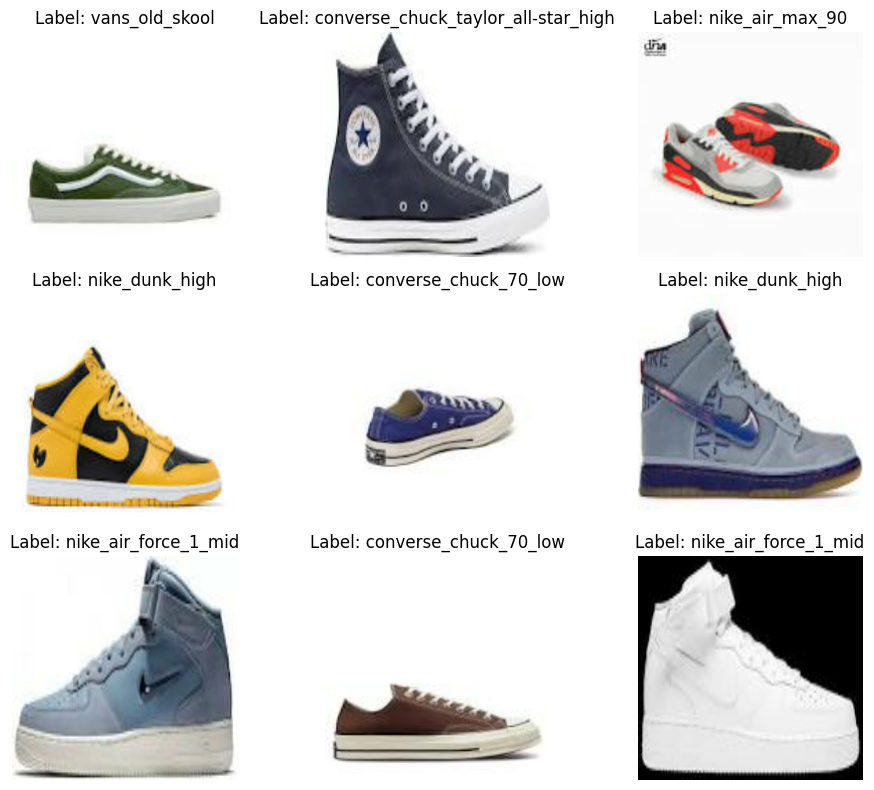

In [250]:
display_image_grid(val_dataset)

**Pasul 8.** Crearea modelului rețelei neuronale convoluționale:

In [251]:
# Model part
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization, GlobalMaxPool2D
from tensorflow.keras.utils import to_categorical # For one-hot encoding


model = Sequential()
#Block 1
model.add(Conv2D(input_shape=(IMG_SIZE, IMG_SIZE, 3), padding='same', filters=32, kernel_size=(7,7)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))

#Block 2
model.add(Conv2D(filters=64, padding='valid', kernel_size=(5,5)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))

#Block 3
model.add(Conv2D(filters=128, padding='valid', kernel_size=(3,3)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D())
model.add(Dropout(0.2))

#Block 4
model.add(Conv2D(filters=256, padding='valid', kernel_size=(3,3)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(Conv2D(filters=256, kernel_size=(3, 3)))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.2))
model.add(GlobalMaxPool2D())
model.add(Dense(units=256))
model.add(Activation('relu'))
model.add(Dropout(0.2))
model.add(Dense(units=NUM_CLASSES)) # Changed units to NUM_CLASSES
model.add(Activation('softmax')) # Changed activation to softmax

/home/catalin/Workspace/Jupiter/venv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Pasul 9.** Vizualizare informații despre modelul creat

In [252]:
print(model.summary())

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_55 (Conv2D)              │ (None, 224, 224, 32)   │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_77 (Activation)      │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_55          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_44 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_55 (Dropout)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 108, 108, 64)   │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_78 (Activation)      │ (None, 108, 108, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 108, 108, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_56 (Dropout)            │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_57 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_79 (Activation)      │ (None, 52, 52, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_57          │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_57 (Dropout)            │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_58 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_80 (Activation)      │ (None, 24, 24, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_58          │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_59 (Conv2D)              │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_81 (Activation)      │ (None, 22, 22, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_59          │ (None, 22, 22, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,096,690 (4.18 MB)

 Trainable params: 1,095,218 (4.18 MB)

 Non-trainable params: 1,472 (5.75 KB)

None


**Pasul 10.** Compilare și antrenarea modelului

In [254]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.utils import to_categorical
import numpy as np
from tensorflow.keras.utils import to_categorical

Val_labels_onehot = to_categorical(Val_labels, num_classes=NUM_CLASSES)

model.compile(
    # loss='categorical_crossentropy',
    loss='sparse_categorical_crossentropy',  # Changed loss function
    optimizer='adam',
    metrics=['accuracy']
)

# Train
history = model.fit(
    train_dataset,
    epochs=10,
    steps_per_epoch=50,
    validation_data=(val_dataset, Val_labels_onehot),
)

print("Training finished")

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.1570 - loss: 3.1909

ValueError: When providing `x` as a tf.data.Dataset, `y` should not be passed. Instead, the targets should be included as part of the tf.data.Dataset.

**Pasul 11.** Evaluarea modelului

In [ ]:
# Evaluating the Loaded model
loss, acc = model.evaluate(val_dataset)

print("Testing Acc:", acc)
print("Testing Loss:", loss)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Get predictions on the validation set
predictions = model.predict(val_dataset)  # Output is usually probabilities
predicted_labels = np.argmax(predictions, axis=1)  # Convert probabilities to class labels

# Get true labels from the validation set (this might require adapting based on how your val_dataset is structured)
true_labels = np.concatenate([y for x, y in val_dataset], axis=0)
true_labels = np.argmax(true_labels, axis=1)

print("Confusion Matrix:\n", confusion_matrix(true_labels, predicted_labels))
print("\nClassification Report:\n", classification_report(true_labels, predicted_labels))